In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv("data.csv")
data.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


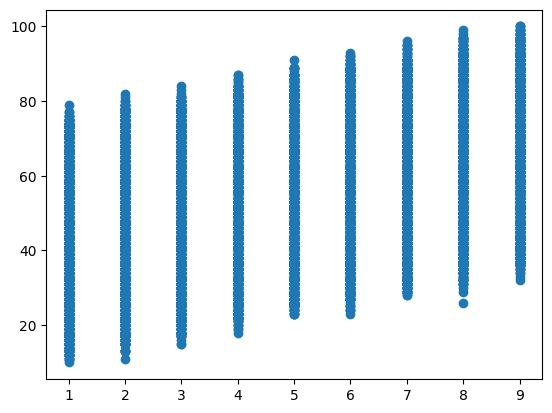

In [6]:
plt.scatter(data['Hours Studied'],data['Performance Index'])
plt.show()

In [7]:
def loss_function(m,b,points):
    total_error= 0 
    for i in range(len(points)):
        x = points.iloc[i]['Hours Studied']
        y = points.iloc[i]['Performance Index']
        total_error += (y - (m*x + b)) ** 2
    return total_error / float(len(points))

In [8]:
def gradient_descent(m_now,b_now,points,L):
    m_gradient = 0
    b_gradient = 0

    n = len(points)

    for i in range(n):
        x = points.iloc[i]['Hours Studied']
        y = points.iloc[i]['Performance Index']
        m_gradient += -(2/n) * x * (y - (m_now*x + b_now))
        b_gradient += -(2/n) * (y - (m_now*x + b_now))

    m = m_now - L * m_gradient
    b = b_now - L * b_gradient

    return m,b

In [9]:
m=0
b=0
L=0.0001
epochs = 1000

for i in range(epochs):
    m,b = gradient_descent(m,b,data,L)
    if(i%50==0):
        print(f"Epoch: {i}")
        print(f"m: {m}, b: {b}")

print(f"Final m: {m}, Final b: {b}")

Epoch: 0
m: 0.05886442000000011, b: 0.01104496000000005
Epoch: 50
m: 2.561190404443011, b: 0.49315561424323856
Epoch: 100
m: 4.365003834756299, b: 0.8641139298918095
Epoch: 150
m: 5.664290563919887, b: 1.1547401968415545
Epoch: 200
m: 6.599166153241202, b: 1.3872959431148084
Epoch: 250
m: 7.2708357648246755, b: 1.577860720696623
Epoch: 300
m: 7.7523996606775745, b: 1.738048852983756
Epoch: 350
m: 8.096657992160377, b: 1.8762494378842234
Epoch: 400
m: 8.341748183116241, b: 1.9985219994683274
Epoch: 450
m: 8.515216799938747, b: 2.1092434152871737
Epoch: 500
m: 8.636960654822838, b: 2.211575190624944
Epoch: 550
m: 8.721351158504083, b: 2.307800969716412
Epoch: 600
m: 8.778768735808143, b: 2.399570319395293
Epoch: 650
m: 8.816711130799396, b: 2.4880748135150266
Epoch: 700
m: 8.840593933276448, b: 2.5741752183587705
Epoch: 750
m: 8.854328797388828, b: 2.658493358395992
Epoch: 800
m: 8.860741087736935, b: 2.7414784707271105
Epoch: 850
m: 8.86187154427821, b: 2.8234551327607593
Epoch: 900
m: 

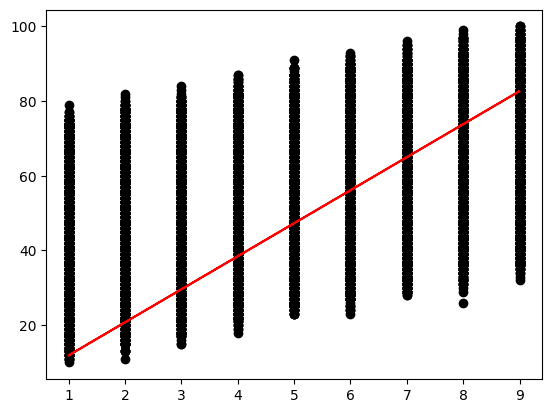

In [ ]:
plt.scatter(data["Hours Studied"],data["Performance Index"],color="black")
plt.plot(data["Hours Studied"],m*data["Hours Studied"]+b,color="red")
plt.show()

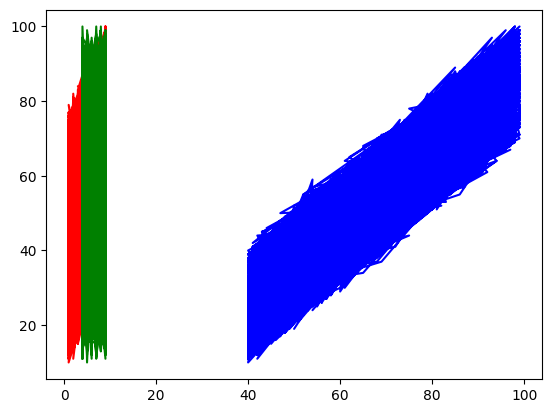

In [12]:
plt.plot(data["Hours Studied"],data["Performance Index"],color="red")
plt.plot(data["Previous Scores"],data["Performance Index"],color="blue")
plt.plot(data["Sleep Hours"],data["Performance Index"],color="green")
plt.show()

In [13]:
def loss_function_multi(weights, bias, points, feature_columns, target_column):
    """
    weights: dictionary like {'Hours Studied': m1, 'Previous Scores': m2, ...}
    """
    total_error = 0
    
    for i in range(len(points)):
        # Calculate prediction
        prediction = bias
        for feature in feature_columns:
            prediction += weights[feature] * points.iloc[i][feature]
        
        # Actual value
        actual = points.iloc[i][target_column]
        
        # Squared error
        total_error += (actual - prediction) ** 2
    
    return total_error / len(points)


In [14]:
def gradient_descent_multi(points, feature_columns, target_column, learning_rate=0.0001, iterations=1000):
    # Initialize weights
    weights = {feature: 0.0 for feature in feature_columns}
    bias = 0.0
    n = len(points)
    
    for iteration in range(iterations):
        # Calculate gradients
        weight_gradients = {feature: 0.0 for feature in feature_columns}
        bias_gradient = 0.0
        
        for i in range(n):
            # Prediction
            prediction = bias
            for feature in feature_columns:
                prediction += weights[feature] * points.iloc[i][feature]
            
            # Error
            actual = points.iloc[i][target_column]
            error = prediction - actual
            
            # Accumulate gradients
            for feature in feature_columns:
                weight_gradients[feature] += (2/n) * error * points.iloc[i][feature]
            bias_gradient += (2/n) * error
        
        # Update weights
        for feature in feature_columns:
            weights[feature] -= learning_rate * weight_gradients[feature]
        bias -= learning_rate * bias_gradient
        
        if iteration % 100 == 0:
            loss = loss_function_multi(weights, bias, points, feature_columns, target_column)
            print(f"Iteration {iteration}: Loss = {loss:.4f}")
    
    return weights, bias

In [15]:
feature_columns = ['Hours Studied', 'Previous Scores', 'Sleep Hours']
target_column = 'Performance Index'

weights, bias = gradient_descent_multi(data, feature_columns, target_column)
print(f"\nWeights: {weights}")
print(f"Bias: {bias}")

Iteration 0: Loss = 77.2575
Iteration 100: Loss = 64.7802
Iteration 200: Loss = 58.7895
Iteration 300: Loss = 54.1115
Iteration 400: Loss = 50.4259
Iteration 500: Loss = 47.4974
Iteration 600: Loss = 45.1519
Iteration 700: Loss = 43.2594
Iteration 800: Loss = 41.7220
Iteration 900: Loss = 40.4651

Weights: {'Hours Studied': np.float64(1.5379462699006379), 'Previous Scores': np.float64(0.7751569545629978), 'Sleep Hours': np.float64(-0.7721766611139222)}
Bias: -0.19549809974428997


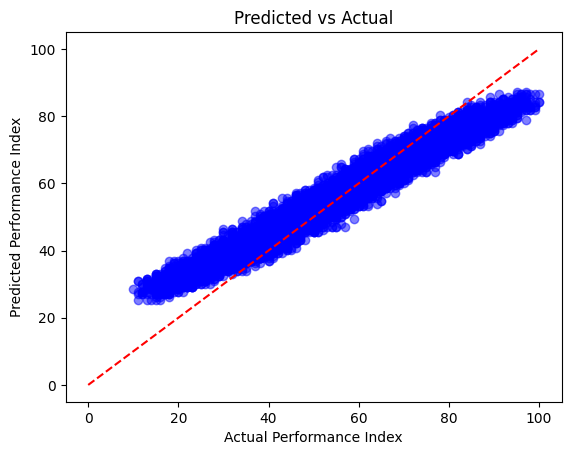

In [20]:
# Calculate predictions using your trained model
predictions = []
for i in range(len(data)):
    prediction = bias
    for feature in feature_columns:
        prediction += weights[feature] * data.iloc[i][feature]
    predictions.append(prediction)

# Plot
plt.scatter(data['Performance Index'], predictions, color='blue', alpha=0.5)
plt.plot([0, 100], [0, 100], color='red', linestyle='--')  # Perfect prediction line
plt.xlabel('Actual Performance Index')
plt.ylabel('Predicted Performance Index')
plt.title('Predicted vs Actual')
plt.show()